In [10]:
import os
import shutil


source = "../dataset/raw/Recyclable"

destination = "../dataset/recyclable_dataset"


os.makedirs(
    destination,
    exist_ok=True
)


for category in os.listdir(source):

    category_path = os.path.join(
        source,
        category
    )


    if os.path.isdir(category_path):

        destination_path = os.path.join(
            destination,
            category
        )


        os.makedirs(
            destination_path,
            exist_ok=True
        )


        for image in os.listdir(category_path):

            shutil.copy(

                os.path.join(
                    category_path,
                    image
                ),

                os.path.join(
                    destination_path,
                    image
                )
            )


print("Recyclable dataset created")

Recyclable dataset created


In [11]:
recyclable_path = "../dataset/recyclable_dataset"


print(
    os.listdir(recyclable_path)
)

['cans_all_type', 'glass_containers', 'paper_products', 'plastic_bottles']


In [12]:
for folder in os.listdir(recyclable_path):

    path = os.path.join(
        recyclable_path,
        folder
    )

    print(
        folder,
        len(os.listdir(path))
    )

cans_all_type 272
glass_containers 142
paper_products 121
plastic_bottles 130


In [13]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input


train_datagen = ImageDataGenerator(

    preprocessing_function=preprocess_input,

    validation_split=0.2,

    rotation_range=20,

    zoom_range=0.2,

    width_shift_range=0.15,

    height_shift_range=0.15,

    horizontal_flip=True,

    brightness_range=[0.8,1.2]

)


val_datagen = ImageDataGenerator(

    preprocessing_function=preprocess_input,

    validation_split=0.2

)

In [14]:
IMG_SIZE=(224,224)

BATCH_SIZE=32


train_data = train_datagen.flow_from_directory(

    recyclable_path,

    target_size=IMG_SIZE,

    batch_size=BATCH_SIZE,

    class_mode="categorical",

    subset="training"

)


val_data = val_datagen.flow_from_directory(

    recyclable_path,

    target_size=IMG_SIZE,

    batch_size=BATCH_SIZE,

    class_mode="categorical",

    subset="validation",

    shuffle=False

)

Found 521 images belonging to 4 classes.
Found 130 images belonging to 4 classes.


In [15]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Dense,
    Dropout,
    GlobalAveragePooling2D
)


base_model = MobileNetV2(

    weights="imagenet",

    include_top=False,

    input_shape=(224,224,3)

)


base_model.trainable=False

In [16]:
recyclable_model = Sequential([

    base_model,

    GlobalAveragePooling2D(),

    Dense(
        128,
        activation="relu"
    ),

    Dropout(0.5),

    Dense(
        4,
        activation="softmax"
    )

])


recyclable_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224 (Functional)    │ (None, 7, 7, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_1           │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │         163,968 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 4)                   │             516 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,422,468 (9.24 MB)

 Trainable params: 164,484 (642.52 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [17]:
from tensorflow.keras.optimizers import Adam


recyclable_model.compile(

    optimizer=Adam(
        learning_rate=0.0001
    ),

    loss="categorical_crossentropy",

    metrics=[
        "accuracy"
    ]

)

In [18]:
history = recyclable_model.fit(

    train_data,

    validation_data=val_data,

    epochs=20

)

C:\Disk D\Year 2 Semester 1\Year2Semester1\Year2Semester1\IT2011 AI & ML\AI ML Project\Waste-Classification-AI\venv\Lib\site-packages\PIL\Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 1/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 26s 1s/step - accuracy: 0.3743 - loss: 1.6505 - val_accuracy: 0.4231 - val_loss: 1.3029
Epoch 2/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 18s 1s/step - accuracy: 0.4338 - loss: 1.3985 - val_accuracy: 0.5308 - val_loss: 1.1031
Epoch 3/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 18s 1s/step - accuracy: 0.4990 - loss: 1.2135 - val_accuracy: 0.6231 - val_loss: 0.9667
Epoch 4/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 18s 1s/step - accuracy: 0.5681 - loss: 1.0799 - val_accuracy: 0.7462 - val_loss: 0.8585
Epoch 5/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 18s 1s/step - accuracy: 0.6104 - loss: 0.9794 - val_accuracy: 0.7692 - val_loss: 0.7836
Epoch 6/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 18s 1s/step - accuracy: 0.6449 - loss: 0.9202 - val_accuracy: 0.7923 - val_loss: 0.7240
Epoch 7/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 18s 1s/step - accuracy: 0.7044 - loss: 0.7771 - val_accuracy: 0.8308 - val_loss: 0.6602
Epoch 8/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 18s 1s/step - accuracy: 0.7102 - loss: 0.7729 - val_accuracy: 0.8077 - val_loss:

In [19]:
base_model = recyclable_model.layers[0]

base_model.trainable = True


for layer in base_model.layers[:-50]:
    layer.trainable = False


print("Fine tuning enabled")

Fine tuning enabled


In [20]:
from tensorflow.keras.optimizers import Adam


recyclable_model.compile(

    optimizer=Adam(
        learning_rate=0.00001
    ),

    loss="categorical_crossentropy",

    metrics=[
        "accuracy"
    ]

)

In [21]:
fine_history = recyclable_model.fit(

    train_data,

    validation_data=val_data,

    epochs=10

)

Epoch 1/10
17/17 ━━━━━━━━━━━━━━━━━━━━ 34s 1s/step - accuracy: 0.7063 - loss: 0.7696 - val_accuracy: 0.8615 - val_loss: 0.3999
Epoch 2/10
17/17 ━━━━━━━━━━━━━━━━━━━━ 19s 1s/step - accuracy: 0.7217 - loss: 0.7499 - val_accuracy: 0.8462 - val_loss: 0.4012
Epoch 3/10
17/17 ━━━━━━━━━━━━━━━━━━━━ 19s 1s/step - accuracy: 0.7678 - loss: 0.6387 - val_accuracy: 0.8385 - val_loss: 0.4015
Epoch 4/10
17/17 ━━━━━━━━━━━━━━━━━━━━ 20s 1s/step - accuracy: 0.7582 - loss: 0.6512 - val_accuracy: 0.8462 - val_loss: 0.4038
Epoch 5/10
17/17 ━━━━━━━━━━━━━━━━━━━━ 20s 1s/step - accuracy: 0.7678 - loss: 0.5999 - val_accuracy: 0.8385 - val_loss: 0.4070
Epoch 6/10
17/17 ━━━━━━━━━━━━━━━━━━━━ 19s 1s/step - accuracy: 0.7946 - loss: 0.5527 - val_accuracy: 0.8385 - val_loss: 0.4072
Epoch 7/10
17/17 ━━━━━━━━━━━━━━━━━━━━ 19s 1s/step - accuracy: 0.7869 - loss: 0.5178 - val_accuracy: 0.8231 - val_loss: 0.4078
Epoch 8/10
17/17 ━━━━━━━━━━━━━━━━━━━━ 19s 1s/step - accuracy: 0.8100 - loss: 0.5413 - val_accuracy: 0.8231 - val_loss:

In [22]:
recyclable_model.save(
    "../models/final_recyclable_model.keras"
)

print("Recyclable model saved")

Recyclable model saved


C:\Disk D\Year 2 Semester 1\Year2Semester1\Year2Semester1\IT2011 AI & ML\AI ML Project\Waste-Classification-AI\venv\Lib\site-packages\PIL\Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


5/5 ━━━━━━━━━━━━━━━━━━━━ 5s 676ms/step


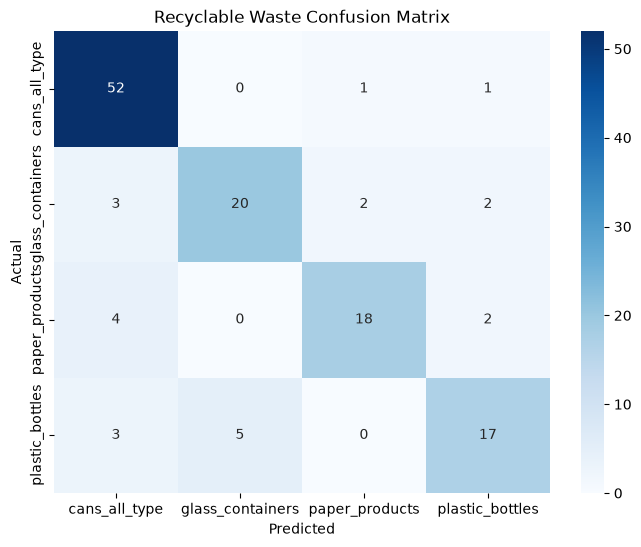

In [23]:
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


predictions = recyclable_model.predict(val_data)


y_pred = np.argmax(
    predictions,
    axis=1
)


y_true = val_data.classes


cm = confusion_matrix(
    y_true,
    y_pred
)


plt.figure(figsize=(8,6))


sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=list(val_data.class_indices.keys()),
    yticklabels=list(val_data.class_indices.keys())
)


plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Recyclable Waste Confusion Matrix")

plt.show()

In [24]:
print(
    classification_report(
        y_true,
        y_pred,
        target_names=list(val_data.class_indices.keys())
    )
)

                  precision    recall  f1-score   support

   cans_all_type       0.84      0.96      0.90        54
glass_containers       0.80      0.74      0.77        27
  paper_products       0.86      0.75      0.80        24
 plastic_bottles       0.77      0.68      0.72        25

        accuracy                           0.82       130
       macro avg       0.82      0.78      0.80       130
    weighted avg       0.82      0.82      0.82       130

